## 7.1 Model Results and Visualizations

It loads the cleaned JSON and fits the same TF-IDF, Logistic Regression, and Random Forest approach used in `BugRadar_ML.ipynb`. Vectorizers are fit on training data only. The regression model uses issue title and body only; dates are used to validate eligible target records, never as features.

Loaded 5,000 cleaned issue documents from C:\Users\riya choudhary\OneDrive\Desktop\BugRadar\data\bugradar_issues_cleaned.json.
Missing/blank category targets: 0; records with no usable title/body: 0.
Duplicate non-null issue IDs: 0.


Classification: 5,000 records; 4,000 train; 1,000 test.
Regression: 3,857 valid closed issues; 3,085 train; 772 test.
Regression MAE: 176.76 hours.


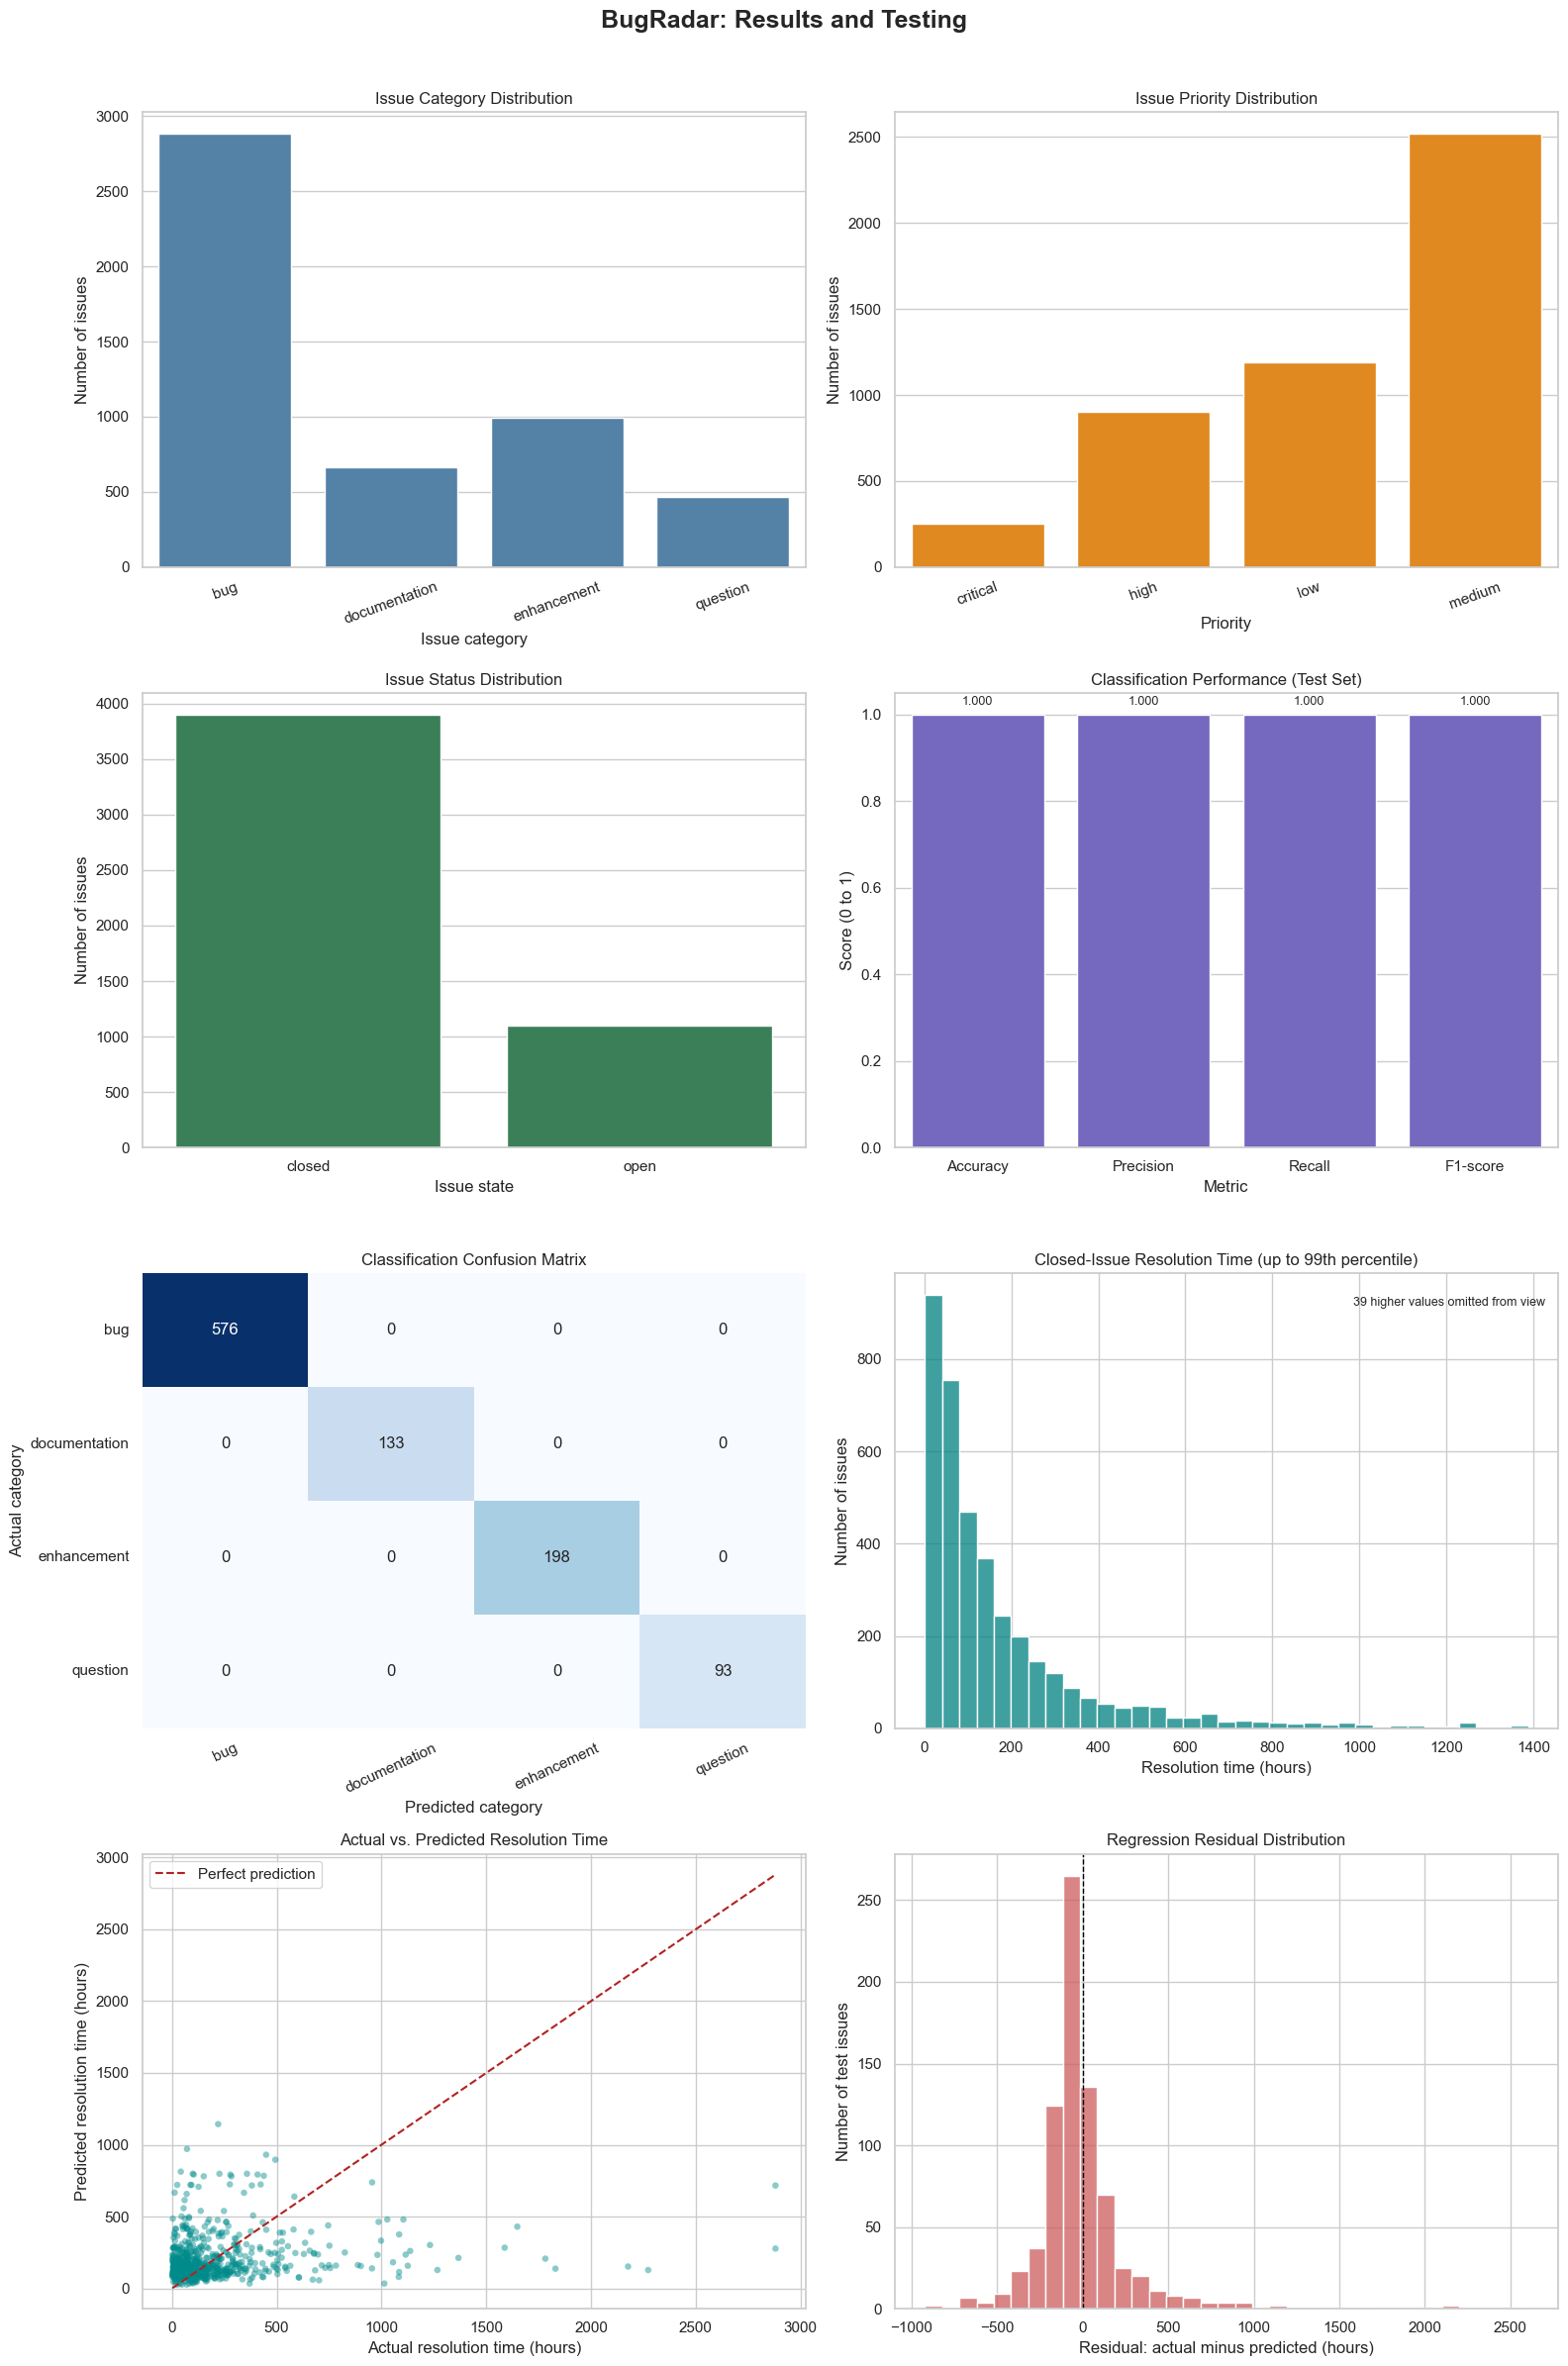

Model results table (computed from this run):


,Task,Records,Train,Test,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),MAE (hours)
0,Issue classification,5000,4000,1000,1.0,1.0,1.0,1.0,NaN
1,Resolution-time regression,3857,3085,772,NaN,NaN,NaN,NaN,176.756458


In [1]:
import json
import math
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             mean_absolute_error, precision_score, recall_score)
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

# Find the project root without assuming the notebook's working directory.
results_project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data' / 'bugradar_issues_cleaned.json').is_file()),
    None,
)
if results_project_root is None:
    raise FileNotFoundError('Could not locate data/bugradar_issues_cleaned.json from the current folder or its parents.')
results_cleaned_path = results_project_root / 'data' / 'bugradar_issues_cleaned.json'
try:
    with results_cleaned_path.open('r', encoding='utf-8') as results_file:
        results_documents = json.load(results_file)
except (OSError, UnicodeDecodeError, json.JSONDecodeError) as results_error:
    raise ValueError(f'Could not load valid UTF-8 JSON from {results_cleaned_path}: {results_error}') from results_error
if not isinstance(results_documents, list) or not results_documents or not all(
        isinstance(document, dict) for document in results_documents):
    raise ValueError('The cleaned dataset must be a non-empty list of document dictionaries.')

required_fields = {'title', 'body', 'issue_category', 'state', 'resolution_hours', 'created_at', 'closed_at'}
available_fields = {key for document in results_documents for key in document}
if required_fields - available_fields:
    raise ValueError(f'Cleaned data is missing required fields: {sorted(required_fields - available_fields)}')
print(f'Loaded {len(results_documents):,} cleaned issue documents from {results_cleaned_path}.')

# Summarize actual data quality before modeling.
missing_target_count = sum(not isinstance(d.get('issue_category'), str) or not d['issue_category'].strip()
                           for d in results_documents)
missing_text_count = sum(not any(isinstance(d.get(field), str) and d[field].strip()
                                  for field in ('title', 'body')) for d in results_documents)
issue_ids = [d.get('id') for d in results_documents if d.get('id') is not None]
duplicate_id_count = len(issue_ids) - len({(type(value).__name__, repr(value)) for value in issue_ids})
print(f'Missing/blank category targets: {missing_target_count}; records with no usable title/body: {missing_text_count}.')
print(f'Duplicate non-null issue IDs: {duplicate_id_count}.')

# Task 5: classify categories from title/body text.
classification_rows = [
    {
        'text': ' '.join(value.strip() for value in (document.get('title'), document.get('body'))
                         if isinstance(value, str) and value.strip()),
        'category': document.get('issue_category'),
    }
    for document in results_documents
]
classification_frame = pd.DataFrame(classification_rows)
classification_frame = classification_frame[
    classification_frame['category'].apply(lambda value: isinstance(value, str) and bool(value.strip()))
].copy()
classification_text = classification_frame['text'].tolist()
classification_target = classification_frame['category'].tolist()
classification_count = len(classification_target)
category_labels = sorted(set(classification_target))
if classification_count < 2 or len(category_labels) < 2:
    raise ValueError('Classification requires at least two records and two categories.')
classification_test_count = math.ceil(0.2 * classification_count)
category_counts = pd.Series(classification_target).value_counts()
classification_stratify = (category_counts.min() >= 2
    and classification_test_count >= len(category_labels)
    and classification_count - classification_test_count >= len(category_labels))
if classification_test_count < 1 or classification_count - classification_test_count < 1:
    raise ValueError('Not enough labeled issues for a train/test split.')
train_text, test_text, train_categories, test_categories = train_test_split(
    classification_text, classification_target, test_size=0.2, random_state=42,
    stratify=classification_target if classification_stratify else None,
)
if len(set(train_categories)) < 2:
    raise ValueError('The classification training split contains fewer than two categories.')
classification_vectorizer = TfidfVectorizer()
try:
    train_features = classification_vectorizer.fit_transform(train_text)
    test_features = classification_vectorizer.transform(test_text)
except ValueError as text_error:
    raise ValueError(f'Could not create classification TF-IDF features: {text_error}') from text_error
classification_model = LogisticRegression(max_iter=1000, random_state=42)
classification_model.fit(train_features, train_categories)
classification_predictions = classification_model.predict(test_features)
classification_metrics = {
    'Accuracy': accuracy_score(test_categories, classification_predictions),
    'Precision': precision_score(test_categories, classification_predictions, average='weighted', zero_division=0),
    'Recall': recall_score(test_categories, classification_predictions, average='weighted', zero_division=0),
    'F1-score': f1_score(test_categories, classification_predictions, average='weighted', zero_division=0),
}

# Task 6: retain only closed issues with valid target values and chronological timestamps.
def parse_results_timestamp(value):
    if not isinstance(value, str) or not value.strip():
        return None
    try:
        parsed = datetime.fromisoformat(value.strip().replace('Z', '+00:00'))
        return parsed.replace(tzinfo=timezone.utc) if parsed.tzinfo is None else parsed
    except ValueError:
        return None

valid_resolution_values = []
for document in results_documents:
    duration = document.get('resolution_hours')
    if (isinstance(document.get('state'), str) and document['state'].strip().casefold() == 'closed'
            and isinstance(duration, (int, float)) and not isinstance(duration, bool)
            and math.isfinite(duration) and duration >= 0):
        created = parse_results_timestamp(document.get('created_at'))
        closed = parse_results_timestamp(document.get('closed_at'))
        if created is not None and closed is not None and closed >= created:
            valid_resolution_values.append(float(duration))
if not valid_resolution_values:
    raise ValueError('No valid closed resolution durations are available for the distribution chart.')

regression_text = []
regression_target = []
for document in results_documents:
    duration = document.get('resolution_hours')
    if (not isinstance(document.get('state'), str) or document['state'].strip().casefold() != 'closed'
            or isinstance(duration, bool) or not isinstance(duration, (int, float))
            or not math.isfinite(duration) or duration < 0):
        continue
    created = parse_results_timestamp(document.get('created_at'))
    closed = parse_results_timestamp(document.get('closed_at'))
    if created is None or closed is None or closed < created:
        continue
    # Do not use closed_at, resolution_hours, or other future information as model features.
    text_parts = [value.strip() for value in (document.get('title'), document.get('body'))
                  if isinstance(value, str) and value.strip()]
    regression_text.append(' '.join(text_parts))
    regression_target.append(float(duration))
regression_count = len(regression_target)
if regression_count < 6:
    raise ValueError(f'Regression needs at least 6 valid closed issues; found {regression_count}.')
regression_test_count = math.ceil(0.2 * regression_count)
if regression_test_count < 2 or regression_count - regression_test_count < 1:
    raise ValueError('Not enough eligible issues for regression train/test evaluation.')
reg_train_text, reg_test_text, reg_train_target, reg_test_target = train_test_split(
    regression_text, regression_target, test_size=0.2, random_state=42)
regression_vectorizer = TfidfVectorizer()
try:
    reg_train_features = regression_vectorizer.fit_transform(reg_train_text)
    reg_test_features = regression_vectorizer.transform(reg_test_text)
except ValueError as text_error:
    raise ValueError(f'Could not create regression TF-IDF features: {text_error}') from text_error
regression_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
regression_model.fit(reg_train_features, reg_train_target)
regression_predictions = regression_model.predict(reg_test_features)
regression_mae = mean_absolute_error(reg_test_target, regression_predictions)

print(f'Classification: {classification_count:,} records; {len(train_categories):,} train; {len(test_categories):,} test.')
print(f'Regression: {regression_count:,} valid closed issues; {len(reg_train_target):,} train; {len(reg_test_target):,} test.')
print(f'Regression MAE: {regression_mae:.2f} hours.')

# Eight readable plots: actual category counts, model metrics, test predictions, and residuals.
figure, axes = plt.subplots(4, 2, figsize=(16, 24))
figure.suptitle('BugRadar: Results and Testing', fontsize=18, fontweight='bold', y=0.995)

category_counts_all = pd.Series([d.get('issue_category') for d in results_documents
    if isinstance(d.get('issue_category'), str) and d['issue_category'].strip()]).value_counts().sort_index()
sns.barplot(x=category_counts_all.index, y=category_counts_all.values, ax=axes[0, 0], color='steelblue')
axes[0, 0].set(title='Issue Category Distribution', xlabel='Issue category', ylabel='Number of issues')
axes[0, 0].tick_params(axis='x', rotation=20)

priority_counts = pd.Series([d.get('priority') for d in results_documents
    if isinstance(d.get('priority'), str) and d['priority'].strip()]).value_counts().sort_index()
sns.barplot(x=priority_counts.index, y=priority_counts.values, ax=axes[0, 1], color='darkorange')
axes[0, 1].set(title='Issue Priority Distribution', xlabel='Priority', ylabel='Number of issues')
axes[0, 1].tick_params(axis='x', rotation=20)

state_counts = pd.Series([d.get('state') for d in results_documents
    if isinstance(d.get('state'), str) and d['state'].strip()]).value_counts().sort_index()
sns.barplot(x=state_counts.index, y=state_counts.values, ax=axes[1, 0], color='seagreen')
axes[1, 0].set(title='Issue Status Distribution', xlabel='Issue state', ylabel='Number of issues')

metric_names = list(classification_metrics)
metric_values = [classification_metrics[name] for name in metric_names]
sns.barplot(x=metric_names, y=metric_values, ax=axes[1, 1], color='slateblue')
axes[1, 1].set(title='Classification Performance (Test Set)', xlabel='Metric', ylabel='Score (0 to 1)', ylim=(0, 1.05))
for metric_index, score in enumerate(metric_values):
    axes[1, 1].text(metric_index, min(score + 0.015, 1.02), f'{score:.3f}', ha='center', va='bottom', fontsize=9)

matrix = confusion_matrix(test_categories, classification_predictions, labels=category_labels)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=category_labels, yticklabels=category_labels, ax=axes[2, 0])
axes[2, 0].set(title='Classification Confusion Matrix', xlabel='Predicted category', ylabel='Actual category')
axes[2, 0].tick_params(axis='x', rotation=25)
axes[2, 0].tick_params(axis='y', rotation=0)

resolution_array = np.asarray(valid_resolution_values)
histogram_limit = float(np.quantile(resolution_array, 0.99))
visible_durations = resolution_array[resolution_array <= histogram_limit]
clipped_count = int((resolution_array > histogram_limit).sum())
sns.histplot(visible_durations, bins=35, ax=axes[2, 1], color='teal')
axes[2, 1].set(title='Closed-Issue Resolution Time (up to 99th percentile)',
               xlabel='Resolution time (hours)', ylabel='Number of issues')
axes[2, 1].text(0.98, 0.95, f'{clipped_count} higher values omitted from view',
                transform=axes[2, 1].transAxes, ha='right', va='top', fontsize=9)

actual_values = np.asarray(reg_test_target)
predicted_values = np.asarray(regression_predictions)
axes[3, 0].scatter(actual_values, predicted_values, alpha=0.45, s=22, color='darkcyan', edgecolors='none')
reference_min = float(min(actual_values.min(), predicted_values.min()))
reference_max = float(max(actual_values.max(), predicted_values.max()))
axes[3, 0].plot([reference_min, reference_max], [reference_min, reference_max],
                linestyle='--', color='firebrick', label='Perfect prediction')
axes[3, 0].set(title='Actual vs. Predicted Resolution Time',
               xlabel='Actual resolution time (hours)', ylabel='Predicted resolution time (hours)')
axes[3, 0].legend()

residuals = actual_values - predicted_values
sns.histplot(residuals, bins=35, ax=axes[3, 1], color='indianred')
axes[3, 1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[3, 1].set(title='Regression Residual Distribution',
               xlabel='Residual: actual minus predicted (hours)', ylabel='Number of test issues')

figure.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

classification_result_table = pd.DataFrame([
    {'Task': 'Issue classification', 'Records': classification_count,
     'Train': len(train_categories), 'Test': len(test_categories),
     'Accuracy': classification_metrics['Accuracy'],
     'Precision (weighted)': classification_metrics['Precision'],
     'Recall (weighted)': classification_metrics['Recall'],
     'F1-score (weighted)': classification_metrics['F1-score'],
     'MAE (hours)': None},
    {'Task': 'Resolution-time regression', 'Records': regression_count,
     'Train': len(reg_train_target), 'Test': len(reg_test_target),
     'Accuracy': None, 'Precision (weighted)': None, 'Recall (weighted)': None,
     'F1-score (weighted)': None, 'MAE (hours)': regression_mae},
])
print('Model results table (computed from this run):')
display(classification_result_table)

## 7.2 MongoDB Database Tests

These checks reuse the project's local settings: database `bugradar_db`, collections `issues_raw` and `issues_cleaned`, server `localhost:27017`. Tests are read-only except for a temporary uniquely identified document used to verify Create, Read, Update, and Delete. A `finally` block attempts to delete only that marked test document.

In [2]:
import uuid

from pymongo import MongoClient
from pymongo.errors import PyMongoError

database_test_results = []
def record_database_test(name, passed, explanation):
    database_test_results.append({
        'Test': name,
        'Result': 'PASS' if passed else 'FAIL',
        'Explanation': explanation,
    })

db_client = None
db_reachable = False
try:
    db_client = MongoClient('mongodb://localhost:27017/',
                            serverSelectionTimeoutMS=4000, connectTimeoutMS=4000)
    ping_response = db_client.admin.command('ping')
    db_reachable = ping_response.get('ok') == 1
    record_database_test('MongoDB connection', db_reachable,
                         'Ping succeeded at localhost:27017.' if db_reachable else f'Unexpected ping response: {ping_response!r}')
except PyMongoError as connection_error:
    record_database_test('MongoDB connection', False,
                         f'Could not connect to localhost:27017: {type(connection_error).__name__}.')

if not db_reachable:
    for test_name in ('Expected collections', 'Raw/cleaned document counts', 'Representative documents',
                      'Read query', 'Aggregation query', 'CRUD create', 'CRUD read', 'CRUD update', 'CRUD delete'):
        record_database_test(test_name, False, 'Not run because MongoDB is unavailable.')
else:
    results_database = db_client['bugradar_db']
    expected_collection_names = {'issues_raw', 'issues_cleaned'}
    try:
        found_collection_names = set(results_database.list_collection_names())
        collections_exist = expected_collection_names.issubset(found_collection_names)
        record_database_test('Expected collections', collections_exist,
            f'Found: {sorted(expected_collection_names & found_collection_names)}.')
    except PyMongoError as collection_error:
        collections_exist = False
        record_database_test('Expected collections', False, f'{type(collection_error).__name__}.')

    if collections_exist:
        raw_collection = results_database['issues_raw']
        cleaned_collection = results_database['issues_cleaned']
        try:
            raw_db_count = raw_collection.count_documents({})
            cleaned_db_count = cleaned_collection.count_documents({})
            raw_file_path = results_project_root / 'data' / 'bugradar issues og.json'
            with raw_file_path.open('r', encoding='utf-8') as raw_test_file:
                raw_file_data = json.load(raw_test_file)
            count_match = (raw_db_count == len(raw_file_data)
                           and cleaned_db_count == len(results_documents))
            record_database_test('Raw/cleaned document counts', count_match,
                f'Raw: DB {raw_db_count}, JSON {len(raw_file_data)}; '
                f'cleaned: DB {cleaned_db_count}, JSON {len(results_documents)}.')

            raw_sample = raw_collection.find_one({}, {'_id': 0, 'id': 1, 'repository': 1, 'labels': 1})
            cleaned_sample = cleaned_collection.find_one({}, {'_id': 0, 'id': 1, 'repository': 1, 'labels': 1})
            nested_ok = (isinstance(raw_sample, dict) and isinstance(raw_sample.get('repository'), dict)
                         and isinstance(raw_sample.get('labels'), list)
                         and isinstance(cleaned_sample, dict) and isinstance(cleaned_sample.get('repository'), dict)
                         and isinstance(cleaned_sample.get('labels'), list))
            record_database_test('Representative nested documents', nested_ok,
                f'Raw sample present={raw_sample is not None}; cleaned sample present={cleaned_sample is not None}; '
                'repository is an object and labels is an array.')

            read_sample = cleaned_collection.find_one({'state': 'open'}, {'_id': 0, 'id': 1, 'state': 1})
            read_query_ok = isinstance(read_sample, dict) and read_sample.get('state') == 'open'
            record_database_test('Read query', read_query_ok,
                'find_one returned an open issue.' if read_query_ok else 'No matching open issue was returned.')

            aggregation = list(cleaned_collection.aggregate([
                {'$match': {'issue_category': {'$type': 'string'}}},
                {'$group': {'_id': '$issue_category', 'issue_count': {'$sum': 1}}},
                {'$sort': {'issue_count': -1, '_id': 1}},
                {'$limit': 5},
            ]))
            aggregation_ok = bool(aggregation) and all('issue_count' in row for row in aggregation)
            record_database_test('Aggregation query', aggregation_ok,
                f'Returned {len(aggregation)} grouped category row(s).')

            # Use a unique marker and id. Always clean only this exact temporary document.
            crud_test_id = f'BUGRADAR_RESULTS_TEST_{uuid.uuid4().hex}'
            crud_marker = 'bugradar_results_testing_temporary'
            crud_created = False
            crud_create_ok = crud_read_ok = crud_update_ok = crud_delete_ok = False
            try:
                test_document = {
                    'id': crud_test_id,
                    'test_marker': crud_marker,
                    'title': 'Temporary results notebook CRUD test',
                    'repository': {'name': 'temporary-test', 'language': 'Python'},
                    'labels': [{'name': 'temporary-test'}],
                }
                inserted = cleaned_collection.insert_one(test_document)
                crud_created = True
                create_check = cleaned_collection.find_one({'_id': inserted.inserted_id,
                                                              'test_marker': crud_marker})
                crud_create_ok = create_check is not None
                record_database_test('CRUD create', crud_create_ok,
                                     'Temporary document was found after insertion.' if crud_create_ok
                                     else 'Inserted document could not be found.')

                read_check = cleaned_collection.find_one({'id': crud_test_id, 'test_marker': crud_marker})
                crud_read_ok = (isinstance(read_check, dict)
                                and isinstance(read_check.get('repository'), dict)
                                and isinstance(read_check.get('labels'), list))
                record_database_test('CRUD read', crud_read_ok,
                                     'Temporary document and nested fields were read.' if crud_read_ok
                                     else 'Temporary document was not read as expected.')

                update_result = cleaned_collection.update_one(
                    {'id': crud_test_id, 'test_marker': crud_marker},
                    {'$set': {'testing.status': 'updated'}},
                )
                updated_document = cleaned_collection.find_one({'id': crud_test_id, 'test_marker': crud_marker})
                crud_update_ok = (update_result.matched_count == 1 and updated_document is not None
                                  and updated_document.get('testing', {}).get('status') == 'updated')
                record_database_test('CRUD update', crud_update_ok,
                                     f'matched={update_result.matched_count}, modified={update_result.modified_count}; '
                                     'updated value verified.' if crud_update_ok else 'Updated value was not verified.')
            except PyMongoError as crud_error:
                for test_name, was_run in (('CRUD create', crud_created), ('CRUD read', crud_create_ok),
                                           ('CRUD update', crud_read_ok)):
                    if not was_run:
                        record_database_test(test_name, False, f'Operation failed: {type(crud_error).__name__}.')
            finally:
                try:
                    if crud_created:
                        delete_result = cleaned_collection.delete_one(
                            {'id': crud_test_id, 'test_marker': crud_marker})
                        still_exists = cleaned_collection.find_one(
                            {'id': crud_test_id, 'test_marker': crud_marker}) is not None
                        crud_delete_ok = delete_result.deleted_count == 1 and not still_exists
                    else:
                        crud_delete_ok = True
                    record_database_test('CRUD delete', crud_delete_ok,
                        'Temporary test document removed and absence verified.' if crud_delete_ok
                        else 'Temporary test document remains or delete count was not one.')
                except PyMongoError as cleanup_error:
                    record_database_test('CRUD delete', False,
                        f'Cleanup verification failed: {type(cleanup_error).__name__}.')
        except (PyMongoError, OSError, UnicodeDecodeError, json.JSONDecodeError, TypeError, KeyError) as test_error:
            record_database_test('Database read/aggregation checks', False,
                                 f'Test could not complete: {type(test_error).__name__}: {test_error}')
    else:
        for test_name in ('Raw/cleaned document counts', 'Representative nested documents',
                          'Read query', 'Aggregation query', 'CRUD create', 'CRUD read', 'CRUD update', 'CRUD delete'):
            record_database_test(test_name, False, 'Not run because one or both expected collections are missing.')

if db_client is not None:
    db_client.close()

database_test_table = pd.DataFrame(database_test_results)
print('Database test results (each test is PASS or FAIL):')
display(database_test_table)
database_pass_count = sum(result['Result'] == 'PASS' for result in database_test_results)
database_fail_count = sum(result['Result'] == 'FAIL' for result in database_test_results)
print(f'Database tests passed: {database_pass_count}; failed: {database_fail_count}.')

Database test results (each test is PASS or FAIL):


,Test,Result,Explanation
0,MongoDB connection,PASS,Ping succeeded at localhost:27017.
1,Expected collections,PASS,"Found: ['issues_cleaned', 'issues_raw']."
2,Raw/cleaned document counts,PASS,"Raw: DB 5000, JSON 5000; cleaned: DB 5000, JSO..."
3,Representative nested documents,PASS,Raw sample present=True; cleaned sample presen...
4,Read query,PASS,find_one returned an open issue.
5,Aggregation query,PASS,Returned 4 grouped category row(s).
6,CRUD create,PASS,Temporary document was found after insertion.
7,CRUD read,PASS,Temporary document and nested fields were read.
8,CRUD update,PASS,"matched=1, modified=1; updated value verified."
9,CRUD delete,PASS,Temporary test document removed and absence ve...


Database tests passed: 10; failed: 0.


## 7.3 Final Results and Testing Summary

The table below is generated from this notebook's measured test metrics and database checks. Classification metrics describe this held-out split; they do not prove generalization to real projects. The regression summary reports MAE only.

In [3]:
final_results_table = pd.DataFrame([
    {'Area': 'Dataset', 'Measure': 'Cleaned issue documents', 'Result': f'{len(results_documents):,}'},
    {'Area': 'Data quality', 'Measure': 'Missing/blank classification targets', 'Result': str(missing_target_count)},
    {'Area': 'Classification', 'Measure': 'Records / train / test',
     'Result': f'{classification_count:,} / {len(train_categories):,} / {len(test_categories):,}'},
    {'Area': 'Classification', 'Measure': 'Accuracy', 'Result': f'{classification_metrics["Accuracy"]:.4f}'},
    {'Area': 'Classification', 'Measure': 'Weighted precision / recall / F1',
     'Result': f'{classification_metrics["Precision"]:.4f} / {classification_metrics["Recall"]:.4f} / {classification_metrics["F1-score"]:.4f}'},
    {'Area': 'Regression', 'Measure': 'Valid closed issues / train / test',
     'Result': f'{regression_count:,} / {len(reg_train_target):,} / {len(reg_test_target):,}'},
    {'Area': 'Regression', 'Measure': 'Mean absolute error (hours)', 'Result': f'{regression_mae:.2f}'},
    {'Area': 'MongoDB', 'Measure': 'Tests passed / failed',
     'Result': f'{database_pass_count} / {database_fail_count}'},
])
print('Final results table:')
display(final_results_table)
print('\nDatabase test summary:')
display(database_test_table)
if database_fail_count:
    print('Warning: one or more MongoDB tests failed; see the explanation column above.')
else:
    print('All recorded MongoDB tests passed.')
print('Interpretation: perfect classification scores require cautious validation; regression MAE is substantial.')

Final results table:


,Area,Measure,Result
0,Dataset,Cleaned issue documents,"5,000"
1,Data quality,Missing/blank classification targets,0
2,Classification,Records / train / test,"5,000 / 4,000 / 1,000"
3,Classification,Accuracy,1.0000
4,Classification,Weighted precision / recall / F1,1.0000 / 1.0000 / 1.0000
5,Regression,Valid closed issues / train / test,"3,857 / 3,085 / 772"
6,Regression,Mean absolute error (hours),176.76
7,MongoDB,Tests passed / failed,10 / 0



Database test summary:


,Test,Result,Explanation
0,MongoDB connection,PASS,Ping succeeded at localhost:27017.
1,Expected collections,PASS,"Found: ['issues_cleaned', 'issues_raw']."
2,Raw/cleaned document counts,PASS,"Raw: DB 5000, JSON 5000; cleaned: DB 5000, JSO..."
3,Representative nested documents,PASS,Raw sample present=True; cleaned sample presen...
4,Read query,PASS,find_one returned an open issue.
5,Aggregation query,PASS,Returned 4 grouped category row(s).
6,CRUD create,PASS,Temporary document was found after insertion.
7,CRUD read,PASS,Temporary document and nested fields were read.
8,CRUD update,PASS,"matched=1, modified=1; updated value verified."
9,CRUD delete,PASS,Temporary test document removed and absence ve...


All recorded MongoDB tests passed.
Interpretation: perfect classification scores require cautious validation; regression MAE is substantial.
